<a href="https://colab.research.google.com/github/anacvetkoo/MOS-projekt/blob/main/notebooks/Ana_teden3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ana, 3. teden

## Namen
Analiza dostopnosti študija in deleža diplom računalništva
na ameriških univerzah v obdobju 2004–2024.

## Raziskovalni vprašanji

**RV1:** Kako so se spreminjale prijave, sprejemi in vpisi na
univerzah Ivy League v primerjavi z drugimi ameriškimi univerzami?

**RV4:** Kako se je spreminjalo število in delež diplom
računalništva ter sorodnih programov (CIP 11)?

# RV1 – Dostopnost študija

## 1. Uvoz in pregled podatkov

V tem delu analiziramo spreminjanje sprejemnih stopenj
na ameriških univerzah v obdobju 2004–2024.

Podatkovni vir: IPEDS (IC2004–IC2013, ADM2014–ADM2024).

Najprej preverimo strukturo podatkov, podatkovne tipe
in manjkajoče vrednosti. Nato določimo ustrezne
institucionalne filtre za primerjavo Ivy League
z drugimi štiriletnimi univerzami.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_rv1 = pd.read_csv("/content/IPEDS_RV1.csv")
print("Dimenzije podatkovne zbirke:", df_rv1.shape)

display(df_rv1.head())

Dimenzije podatkovne zbirke: (94360, 8)


,UNITID,APPLCN,ADMSSN,ENRLT,leto,vir,ivy_league,univerza
0,100654,6197.0,2944.0,1259.0,2004,IC2004,False,NaN
1,100663,4318.0,3710.0,1628.0,2004,IC2004,False,NaN
2,100690,NaN,NaN,NaN,2004,IC2004,False,NaN
3,100706,1743.0,1559.0,681.0,2004,IC2004,False,NaN
4,100724,11462.0,5779.0,1249.0,2004,IC2004,False,NaN


In [2]:
print("Podatkovni tipi:")
print(df_rv1.dtypes)

print("\nManjkajoče vrednosti:")
print(df_rv1.isna().sum())

print("\nObdobje:")
print(df_rv1["leto"].min(), "-", df_rv1["leto"].max())

print("\nŠtevilo različnih institucij:")
print(df_rv1["UNITID"].nunique())

Podatkovni tipi:
UNITID          int64
APPLCN        float64
ADMSSN        float64
ENRLT         float64
leto            int64
vir            object
ivy_league       bool
univerza       object
dtype: object

Manjkajoče vrednosti:
UNITID            0
APPLCN        45362
ADMSSN        45598
ENRLT         45598
leto              0
vir               0
ivy_league        0
univerza      94192
dtype: int64

Obdobje:
2004 - 2024

Število različnih institucij:
9061


In [3]:
# Preverjanje veljavnosti podatkov za RV1

print("Vrstice z veljavnimi prijavami in sprejemi:")

veljavni = (
    df_rv1["APPLCN"].notna() &
    df_rv1["ADMSSN"].notna() &
    (df_rv1["APPLCN"] > 0) &
    (df_rv1["ADMSSN"] >= 0) &
    (df_rv1["ADMSSN"] <= df_rv1["APPLCN"])
)

print(veljavni.sum(), "od", len(df_rv1))

print("\nNeveljavni podatki:")

print("Prijave <= 0:",
      (df_rv1["APPLCN"] <= 0).sum())

print("Sprejemi < 0:",
      (df_rv1["ADMSSN"] < 0).sum())

print("Sprejemi > prijave:",
      (df_rv1["ADMSSN"] > df_rv1["APPLCN"]).sum())

print("\nPodvojene kombinacije UNITID in leto:")

print(df_rv1.duplicated(subset=["UNITID", "leto"]).sum())

print("\nŠtevilo Ivy League institucij:")

print(df_rv1.loc[df_rv1["ivy_league"], "UNITID"].nunique())

Vrstice z veljavnimi prijavami in sprejemi:
48645 od 94360

Neveljavni podatki:
Prijave <= 0: 353
Sprejemi < 0: 0
Sprejemi > prijave: 0

Podvojene kombinacije UNITID in leto:
0

Število Ivy League institucij:
8


In [4]:
# Preverjanje manjkajočih podatkov po letih

pregled = df_rv1.groupby("leto").agg(
    skupaj=("UNITID", "count"),
    prijave=("APPLCN", "count"),
    sprejemi=("ADMSSN", "count"),
    vpisi=("ENRLT", "count")
)

# Število zapisov z veljavnimi prijavami in sprejemi
pregled["veljavni_za_stopnjo"] = (
    df_rv1[veljavni].groupby("leto").size()
)

# Delež veljavnih zapisov
pregled["delez_veljavnih"] = (
    pregled["veljavni_za_stopnjo"] /
    pregled["skupaj"] * 100
).round(1)

display(pregled)

,skupaj,prijave,sprejemi,vpisi,veljavni_za_stopnjo,delez_veljavnih
leto,,,,,,
2004,6804,2831,2831,2831,2816,41.4
2005,6844,2855,2855,2840,2845,41.6
2006,6891,2903,2903,2888,2897,42.0
2007,6902,2898,2899,2885,2872,41.6
2008,7034,2848,2848,2847,2834,40.3
2009,7135,2809,2809,2809,2804,39.3
2010,7367,2331,2331,2343,2329,31.6
2011,7591,2382,2381,2425,2377,31.3
2012,7651,2355,2355,2391,2333,30.5


In [5]:
# Branje podatkov za RV1 in institucionalnih podatkov

df_rv1 = pd.read_csv("/content/IPEDS_RV1.csv")

df_institucije = pd.read_csv(
    "/content/IPEDS_institucije_2004_2024.csv"
)

print("RV1:", df_rv1.shape)
print("Institucije:", df_institucije.shape)

print("\nStolpci RV1:")
print(df_rv1.columns.tolist())

print("\nStolpci institucionalne zbirke:")
print(df_institucije.columns.tolist())

RV1: (94360, 8)
Institucije: (147769, 6)

Stolpci RV1:
['UNITID', 'APPLCN', 'ADMSSN', 'ENRLT', 'leto', 'vir', 'ivy_league', 'univerza']

Stolpci institucionalne zbirke:
['UNITID', 'INSTNM', 'CONTROL', 'ICLEVEL', 'SECTOR', 'leto']


In [6]:
# Povezovanje podatkov RV1 z institucionalnimi podatki

df_rv1_povezano = pd.merge(
    df_rv1,
    df_institucije[
        ["UNITID", "leto", "CONTROL", "ICLEVEL", "SECTOR"]
    ],
    on=["UNITID", "leto"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Velikost pred povezovanjem:", df_rv1.shape)
print("Velikost po povezovanju:", df_rv1_povezano.shape)

print("\nUspešnost povezovanja:")
print(df_rv1_povezano["_merge"].value_counts())

Velikost pred povezovanjem: (94360, 8)
Velikost po povezovanju: (94360, 12)

Uspešnost povezovanja:
_merge
both          94360
left_only         0
right_only        0
Name: count, dtype: int64


za raziskavo sem univerze razdelila v 3 skupine:
- Ivy League
- Druge javne 4-letne univerze
- Druge zasebne neprofitne štiriletne univerze

In [7]:
# Preverimo oznake Ivy League in institucionalne kategorije

print("Vrednosti ivy_league:")
print(df_rv1_povezano["ivy_league"].value_counts(dropna=False))

print("\nVrednosti CONTROL:")
print(df_rv1_povezano["CONTROL"].value_counts(dropna=False))

print("\nVrednosti ICLEVEL:")
print(df_rv1_povezano["ICLEVEL"].value_counts(dropna=False))

print("\nKombinacije CONTROL in ICLEVEL za Ivy League:")
display(
    df_rv1_povezano[
        df_rv1_povezano["ivy_league"].astype(str).str.lower().isin(["true", "1"])
    ][["CONTROL", "ICLEVEL"]].value_counts()
)

Vrednosti ivy_league:
ivy_league
False    94192
True       168
Name: count, dtype: int64

Vrednosti CONTROL:
CONTROL
3    33556
2    32695
1    28109
Name: count, dtype: int64

Vrednosti ICLEVEL:
ICLEVEL
1    49399
2    24752
3    20209
Name: count, dtype: int64

Kombinacije CONTROL in ICLEVEL za Ivy League:


,,count
CONTROL,ICLEVEL,
2,1,168


In [8]:
#izbor štiriletnih javnih in zasebnih neprofitnih institucij
df_rv1_analiza = df_rv1_povezano[
    (df_rv1_povezano["ICLEVEL"] == 1) &
    (df_rv1_povezano["CONTROL"].isin([1, 2]))
].copy()

#določitev primerjalnih skupin
df_rv1_analiza["skupina"] = "Druge zasebne neprofitne"

df_rv1_analiza.loc[
    df_rv1_analiza["CONTROL"] == 1, "skupina"
] = "Druge javne"

df_rv1_analiza.loc[
    df_rv1_analiza["ivy_league"] == True, "skupina"
] = "Ivy League"

#preverjanje števila zapisov po skupinah
print(df_rv1_analiza["skupina"].value_counts())

#preverjanje števila različnih univerz po skupinah
print("\nŠtevilo različnih univerz:")
print(df_rv1_analiza.groupby("skupina")["UNITID"].nunique())

skupina
Druge zasebne neprofitne    28719
Druge javne                 13268
Ivy League                    168
Name: count, dtype: int64

Število različnih univerz:
skupina
Druge javne                  804
Druge zasebne neprofitne    1955
Ivy League                     8
Name: UNITID, dtype: int64


In [9]:
#preverjanje števila univerz po letih in primerjalnih skupinah
pregled_univerz = df_rv1_analiza.pivot_table(
    index="leto",
    columns="skupina",
    values="UNITID",
    aggfunc="nunique"
)

display(pregled_univerz)

skupina,Druge javne,Druge zasebne neprofitne,Ivy League
leto,,,
2004,700,1647,8
2005,700,1639,8
2006,705,1627,8
2007,714,1629,8
2008,714,1626,8
2009,732,1633,8
2010,737,1633,8
2011,741,1645,8
2012,749,1650,8


In [10]:
#označevanje zapisov z veljavnimi podatki za izračun stopnje sprejema
df_rv1_analiza["veljavno"] = (
    (df_rv1_analiza["APPLCN"] > 0) &
    (df_rv1_analiza["ADMSSN"] >= 0) &
    (df_rv1_analiza["ADMSSN"] <= df_rv1_analiza["APPLCN"])
)

#število univerz z veljavnimi podatki po letih in skupinah
pregled_veljavnih = df_rv1_analiza[
    df_rv1_analiza["veljavno"]
].pivot_table(
    index="leto",
    columns="skupina",
    values="UNITID",
    aggfunc="nunique"
)

display(pregled_veljavnih)

skupina,Druge javne,Druge zasebne neprofitne,Ivy League
leto,,,
2004,519,1112,8
2005,520,1104,8
2006,523,1100,8
2007,533,1103,8
2008,532,1100,8
2009,535,1107,8
2010,538,1081,8
2011,542,1092,8
2012,545,1100,8


In [11]:
#izbor zapisov z veljavnimi podatki
df_rv1_veljavni = df_rv1_analiza[
    df_rv1_analiza["veljavno"]
].copy()

#seštevanje prijav in sprejemov po letih in skupinah
stopnje_sprejema = df_rv1_veljavni.groupby(
    ["leto", "skupina"]
)[["APPLCN", "ADMSSN"]].sum().reset_index()

#izračun stopnje sprejema v odstotkih
stopnje_sprejema["stopnja_sprejema"] = (
    stopnje_sprejema["ADMSSN"] /
    stopnje_sprejema["APPLCN"] * 100
)

#prikaz stopenj sprejema po letih
pregled_stopenj = stopnje_sprejema.pivot(
    index="leto",
    columns="skupina",
    values="stopnja_sprejema"
).round(2)

display(pregled_stopenj)

skupina,Druge javne,Druge zasebne neprofitne,Ivy League
leto,,,
2004,63.75,58.27,16.92
2005,63.29,57.50,15.56
2006,63.17,55.40,14.50
2007,62.50,53.92,13.64
2008,61.18,53.25,13.37
2009,60.46,54.23,12.48
2010,60.20,53.48,11.19
2011,59.05,52.34,10.54
2012,59.49,52.52,9.80


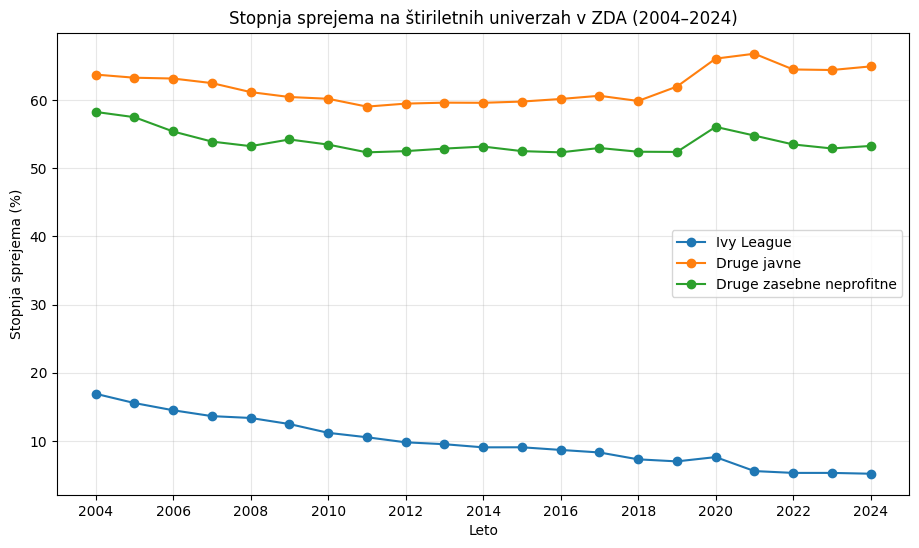

In [12]:
import matplotlib.pyplot as plt

#prikaz gibanja stopnje sprejema po primerjalnih skupinah
plt.figure(figsize=(11, 6))

plt.plot(
    pregled_stopenj.index,
    pregled_stopenj["Ivy League"],
    marker="o",
    label="Ivy League"
)

plt.plot(
    pregled_stopenj.index,
    pregled_stopenj["Druge javne"],
    marker="o",
    label="Druge javne"
)

plt.plot(
    pregled_stopenj.index,
    pregled_stopenj["Druge zasebne neprofitne"],
    marker="o",
    label="Druge zasebne neprofitne"
)

#naslov in oznake osi
plt.title("Stopnja sprejema na štiriletnih univerzah v ZDA (2004–2024)")
plt.xlabel("Leto")
plt.ylabel("Stopnja sprejema (%)")

#prikaz vseh let na vodoravni osi
plt.xticks(range(2004, 2025, 2))

#legenda in mreža
plt.legend()
plt.grid(True, alpha=0.3)

#prikaz grafa
plt.show()

Med letoma 2004 in 2024 se je agregirana stopnja sprejema na Ivy League zmanjšala s 16,92 % na 5,19 %, medtem ko je pri drugih javnih štiriletnih univerzah ostala razmeroma stabilna.

Ivy League je torej postala izrazito bolj selektivna.

Zakaj se je stopnja sprejema na Ivy League tako močno znižala?

bolj poglobljeno v Ivy League:

In [13]:
#seštevanje prijav, sprejemov in vpisov po letih in skupinah
pregled_rv1 = df_rv1_analiza.groupby(
    ["leto", "skupina"]
)[["APPLCN", "ADMSSN", "ENRLT"]].sum(min_count=1).reset_index()

#prikaz gibanja kazalnikov za ivy league
display(
    pregled_rv1[
        pregled_rv1["skupina"] == "Ivy League"
    ]
)

,leto,skupina,APPLCN,ADMSSN,ENRLT
2,2004,Ivy League,134501.0,22762.0,13490.0
5,2005,Ivy League,149966.0,23340.0,13654.0
8,2006,Ivy League,160346.0,23250.0,13706.0
11,2007,Ivy League,168825.0,23021.0,13527.0
14,2008,Ivy League,180233.0,24094.0,13794.0
17,2009,Ivy League,195354.0,24385.0,13965.0
20,2010,Ivy League,219712.0,24583.0,13889.0
23,2011,Ivy League,231959.0,24448.0,14108.0
26,2012,Ivy League,243126.0,23833.0,14091.0
29,2013,Ivy League,245660.0,23381.0,14000.0


In [14]:
#izbor podatkov za ivy league
ivy_trendi = pregled_rv1[
    pregled_rv1["skupina"] == "Ivy League"
].copy()

#ureditev podatkov po letih
ivy_trendi = ivy_trendi.sort_values("leto")

#izračun indeksov glede na leto 2004
for stolpec in ["APPLCN", "ADMSSN", "ENRLT"]:
    osnovna_vrednost = ivy_trendi.loc[
        ivy_trendi["leto"] == 2004, stolpec
    ].iloc[0]

    ivy_trendi[stolpec + "_indeks"] = (
        ivy_trendi[stolpec] / osnovna_vrednost * 100
    )

#prikaz indeksiranih vrednosti
display(
    ivy_trendi[
        ["leto", "APPLCN_indeks", "ADMSSN_indeks", "ENRLT_indeks"]
    ].round(1)
)

,leto,APPLCN_indeks,ADMSSN_indeks,ENRLT_indeks
2,2004,100.0,100.0,100.0
5,2005,111.5,102.5,101.2
8,2006,119.2,102.1,101.6
11,2007,125.5,101.1,100.3
14,2008,134.0,105.9,102.3
17,2009,145.2,107.1,103.5
20,2010,163.4,108.0,103.0
23,2011,172.5,107.4,104.6
26,2012,180.8,104.7,104.5
29,2013,182.6,102.7,103.8


Število prijav na Ivy League je močno naraslo (za 212,9%), medtem ko se število sprejetih in vpisanih ni sorazmerno spremenilo. Sprejemi so se zmanjšali za 4%, vpisi pa povečali za 11,1%.

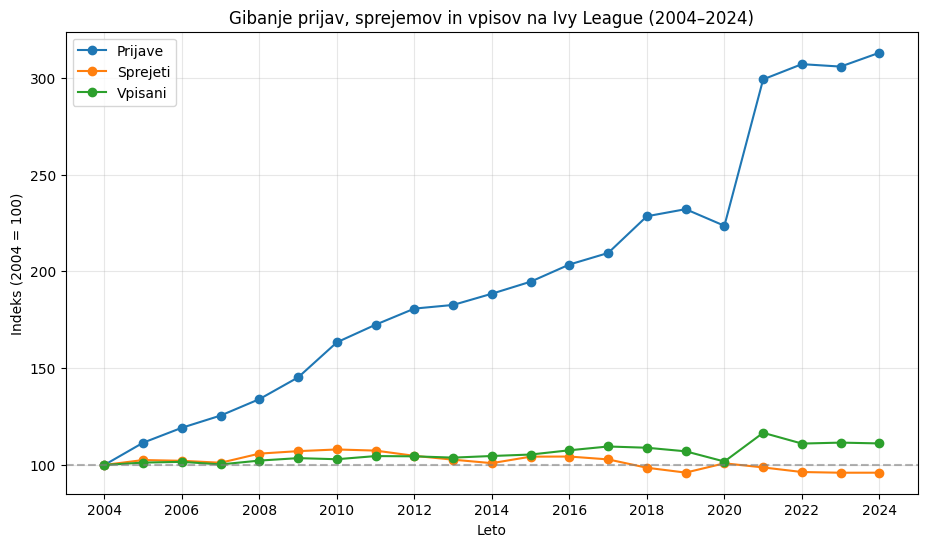

In [15]:
#prikaz gibanja prijav, sprejemov in vpisov na ivy league
plt.figure(figsize=(11, 6))

plt.plot(
    ivy_trendi["leto"],
    ivy_trendi["APPLCN_indeks"],
    marker="o",
    label="Prijave"
)

plt.plot(
    ivy_trendi["leto"],
    ivy_trendi["ADMSSN_indeks"],
    marker="o",
    label="Sprejeti"
)

plt.plot(
    ivy_trendi["leto"],
    ivy_trendi["ENRLT_indeks"],
    marker="o",
    label="Vpisani"
)

#označitev izhodiščne vrednosti indeksa
plt.axhline(y=100, color="gray", linestyle="--", alpha=0.6)

#naslov in oznake osi
plt.title("Gibanje prijav, sprejemov in vpisov na Ivy League (2004–2024)")
plt.xlabel("Leto")
plt.ylabel("Indeks (2004 = 100)")

#ureditev osi in legende
plt.xticks(range(2004, 2025, 2))
plt.legend()
plt.grid(True, alpha=0.3)

import os

#ustvarjanje mape za shranjevanje grafov, če še ne obstaja
os.makedirs("figures", exist_ok=True)

#shranjevanje grafa
plt.savefig("figures/RV1_ivy_trendi.png", dpi=300, bbox_inches="tight")

#prikaz grafa
plt.show()

trendi:
- prijave: Med letoma 2004 in 2024 se je njihovo število povečalo za 212,9 %. Posebej izstopa skok med letoma 2020 in 2021, ko je indeks narasel z 223,5 na 299,2.
- sprejemi: Število sprejetih kandidatov je ostalo razmeroma stabilno. Leta 2024 je bilo celo za 4 % nižje kot leta 2004.
- vpisi: Število dejansko vpisanih kandidatov se je povečalo za 11,1 %, kar je bistveno manj od rasti prijav.

Močna rast števila prijav ob razmeroma stabilnem številu sprejetih kandidatov pojasnjuje izrazito znižanje stopnje sprejema na Ivy League.

RV4 – spreminjanje števila in deleža diplomantov računalništva ter sorodnih programov na ameriških univerzah (2004–2024).

In [16]:
#nalaganje podatkov o podeljenih diplomah
df_rv4 = pd.read_csv("/content/IPEDS_RV4_nova.csv", low_memory=False)

#preverjanje velikosti in strukture zbirke
print("Dimenzije zbirke:", df_rv4.shape)

print("\nStolpci:")
print(df_rv4.columns.tolist())

print("\nObdobje:")
print(df_rv4["leto"].min(), "-", df_rv4["leto"].max())

#pregled prvih petih zapisov
display(df_rv4.head())

Dimenzije zbirke: (5801764, 8)

Stolpci:
['UNITID', 'CIPCODE', 'AWLEVEL', 'MAJORNUM', 'CRACE24', 'leto', 'vir', 'CTOTALT']

Obdobje:
2004 - 2024


,UNITID,CIPCODE,AWLEVEL,MAJORNUM,CRACE24,leto,vir,CTOTALT
0,100654,1.0000,5,1,4.0,2004,C2004_A,NaN
1,100654,1.0102,7,1,10.0,2004,C2004_A,NaN
2,100654,1.0103,5,1,3.0,2004,C2004_A,NaN
3,100654,1.0901,5,1,6.0,2004,C2004_A,NaN
4,100654,1.1001,5,1,5.0,2004,C2004_A,NaN


In [17]:
#preverjanje kod za raven diplome in študijsko področje
print("Vrednosti AWLEVEL:")
print(df_rv4["AWLEVEL"].value_counts().sort_index())

print("\nVrednosti MAJORNUM:")
print(df_rv4["MAJORNUM"].value_counts().sort_index())

#preverjanje agregatnih kod CIP za diplome prve stopnje
df_rv4_bachelor = df_rv4[
    (df_rv4["AWLEVEL"] == 5) &
    (df_rv4["MAJORNUM"] == 1)
]

print("\nZapisi za CIPCODE 11 in 99:")
print(
    df_rv4_bachelor[
        df_rv4_bachelor["CIPCODE"].isin([11, 99])
    ]["CIPCODE"].value_counts()
)

#preverjanje razpoložljivosti obeh spremenljivk za število diplom
print("\nRazpoložljivost CRACE24 in CTOTALT po letih:")
display(
    df_rv4_bachelor.groupby("leto")[
        ["CRACE24", "CTOTALT"]
    ].count()
)

Vrednosti AWLEVEL:
AWLEVEL
1      419642
2      611711
3     1005253
4       64844
5     2171193
6      158132
7      816635
8       80199
9       56226
10       7094
11        985
17     189435
18      38599
19       5270
20      19975
21     156571
Name: count, dtype: int64

Vrednosti MAJORNUM:
MAJORNUM
1    5188090
2     613674
Name: count, dtype: int64

Zapisi za CIPCODE 11 in 99:
CIPCODE
99.0    53343
Name: count, dtype: int64

Razpoložljivost CRACE24 in CTOTALT po letih:


,CRACE24,CTOTALT
leto,,
2004,63905,0
2005,66018,0
2006,67578,0
2007,68646,0
2008,0,69464
2009,0,71815
2010,0,73828
2011,0,74211
2012,0,75432


In [18]:
#izbor kod cip, ki spadajo na področje računalništva
cip_racunalnistvo = df_rv4_bachelor[
    (df_rv4_bachelor["CIPCODE"] >= 11) &
    (df_rv4_bachelor["CIPCODE"] < 12)
]

#pregled kod računalništva in njihove pogostosti
print("Število različnih kod CIP 11:")
print(cip_racunalnistvo["CIPCODE"].nunique())

print("\nKode CIP 11:")
print(
    cip_racunalnistvo["CIPCODE"]
    .value_counts()
    .sort_index()
)

Število različnih kod CIP 11:
32

Kode CIP 11:
CIPCODE
11.0101    14005
11.0102       82
11.0103     5952
11.0104      424
11.0105       37
11.0199      687
11.0201     1937
11.0202      303
11.0203        9
11.0204       71
11.0205        9
11.0299      113
11.0301      229
11.0401     5739
11.0501     1316
11.0601        5
11.0701    13386
11.0801     2442
11.0802      368
11.0803      985
11.0804      222
11.0899      746
11.0901     1970
11.0902       33
11.1001      814
11.1002      463
11.1003     4038
11.1004      577
11.1005      222
11.1006      190
11.1099      913
11.9999     1235
Name: count, dtype: int64


In [19]:
#priprava podatkov o diplomah prve stopnje
df_rv4_analiza = df_rv4_bachelor.copy()

#združitev spremenljivk za število diplom glede na leto
df_rv4_analiza["stevilo_diplom"] = df_rv4_analiza["CTOTALT"]

df_rv4_analiza.loc[
    df_rv4_analiza["leto"] <= 2007, "stevilo_diplom"
] = df_rv4_analiza["CRACE24"]

#preverjanje manjkajočih in neveljavnih vrednosti
print("Manjkajoče vrednosti:")
print(df_rv4_analiza["stevilo_diplom"].isna().sum())

print("\nNegativne vrednosti:")
print((df_rv4_analiza["stevilo_diplom"] < 0).sum())

#preverjanje razpoložljivosti podatkov po letih
display(
    df_rv4_analiza.groupby("leto")["stevilo_diplom"].agg(
        ["count", "min", "max"]
    )
)

Manjkajoče vrednosti:
0

Negativne vrednosti:
0


,count,min,max
leto,,,
2004,63905,0.0,9134.0
2005,66018,0.0,9840.0
2006,67578,0.0,10037.0
2007,68646,0.0,13257.0
2008,69464,0.0,15117.0
2009,71815,0.0,14576.0
2010,73828,0.0,17647.0
2011,74211,0.0,21638.0
2012,75432,0.0,32432.0


In [20]:
#izbor zapisov s skupnim številom diplom
df_rv4_skupaj = df_rv4_analiza[
    df_rv4_analiza["CIPCODE"] == 99
].copy()

#preverjanje števila agregatnih zapisov po letih
print("Število zapisov CIPCODE 99 po letih:")
print(df_rv4_skupaj.groupby("leto").size())

#preverjanje podvojenih agregatnih zapisov za isto univerzo in leto
print("\nPodvojene kombinacije UNITID in leto:")
print(df_rv4_skupaj.duplicated(["UNITID", "leto"]).sum())

#preverjanje števila diplom v agregatnih zapisih
print("\nOpisna statistika skupnega števila diplom:")
display(df_rv4_skupaj["stevilo_diplom"].describe())

Število zapisov CIPCODE 99 po letih:
leto
2004    2285
2005    2354
2006    2379
2007    2430
2008    2479
2009    2543
2010    2617
2011    2685
2012    2741
2013    2799
2014    2769
2015    2773
2016    2614
2017    2604
2018    2556
2019    2484
2020    2444
2021    2440
2022    2462
2023    2445
2024    2440
dtype: int64

Podvojene kombinacije UNITID in leto:
0

Opisna statistika skupnega števila diplom:


,stevilo_diplom
count,53343.000000
mean,715.098513
std,1422.170231
min,0.000000
25%,48.000000
50%,236.000000
75%,659.000000
max,32432.000000


In [21]:
#seštevanje diplom po posameznih študijskih programih
vsota_programov = df_rv4_analiza[
    df_rv4_analiza["CIPCODE"] != 99
].groupby(
    ["UNITID", "leto"]
)["stevilo_diplom"].sum().reset_index(name="vsota_programov")

#primerjava s skupnim številom diplom iz kode cip 99
preverjanje_cip99 = df_rv4_skupaj[
    ["UNITID", "leto", "stevilo_diplom"]
].merge(
    vsota_programov,
    on=["UNITID", "leto"],
    how="left"
)

#izračun razlike med obema vrednostma
preverjanje_cip99["razlika"] = (
    preverjanje_cip99["stevilo_diplom"] -
    preverjanje_cip99["vsota_programov"]
)

#preverjanje ujemanja
print("Število primerjanih zapisov:", len(preverjanje_cip99))

print("\nŠtevilo zapisov brez podatkov o posameznih programih:")
print(preverjanje_cip99["vsota_programov"].isna().sum())

print("\nŠtevilo zapisov z razliko:")
print((preverjanje_cip99["razlika"].abs() > 0.01).sum())

print("\nOpisna statistika razlik:")
display(preverjanje_cip99["razlika"].describe())

Število primerjanih zapisov: 53343

Število zapisov brez podatkov o posameznih programih:
0

Število zapisov z razliko:
0

Opisna statistika razlik:


,razlika
count,53343.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


potrjeno: CIPCODE 99 je agregat za skupno število diplom prve stopnje

In [22]:
#izračun števila diplom s področja računalništva po univerzah in letih
diplome_cip11 = df_rv4_analiza[
    (df_rv4_analiza["CIPCODE"] >= 11) &
    (df_rv4_analiza["CIPCODE"] < 12)
].groupby(
    ["UNITID", "leto"]
)["stevilo_diplom"].sum().reset_index(name="diplome_cip11")

#priprava skupnega števila diplom prve stopnje
diplome_skupaj = df_rv4_skupaj[
    ["UNITID", "leto", "stevilo_diplom"]
].rename(columns={"stevilo_diplom": "diplome_skupaj"})

#povezava skupnega števila diplom s številom diplom računalništva
df_rv4_delezi = diplome_skupaj.merge(
    diplome_cip11,
    on=["UNITID", "leto"],
    how="left" #ohranitev tudi univerz, ki v določenem letu niso podelile nobene diplome s področja računalništva
)

#univerze brez diplom cip 11 dobijo vrednost 0
df_rv4_delezi["diplome_cip11"] = (
    df_rv4_delezi["diplome_cip11"].fillna(0)
)

#izračun deleža diplom računalništva v odstotkih
df_rv4_delezi["delez_cip11"] = (
    df_rv4_delezi["diplome_cip11"] /
    df_rv4_delezi["diplome_skupaj"].replace(0, float("nan"))
) * 100

#preverjanje rezultatov
print("Število zapisov:", len(df_rv4_delezi))

print("\nManjkajoči deleži:")
print(df_rv4_delezi["delez_cip11"].isna().sum())

print("\nDeleži nad 100 %:")
print((df_rv4_delezi["delez_cip11"] > 100).sum())

print("\nPrvih pet zapisov:")
display(df_rv4_delezi.head())

Število zapisov: 53343

Manjkajoči deleži:
1916

Deleži nad 100 %:
0

Prvih pet zapisov:


,UNITID,leto,diplome_skupaj,diplome_cip11,delez_cip11
0,100654,2004,589.0,44.0,7.470289
1,100663,2004,1575.0,54.0,3.428571
2,100690,2004,112.0,0.0,0.000000
3,100706,2004,810.0,46.0,5.679012
4,100724,2004,589.0,85.0,14.431239


In [23]:
#preverjanje vzroka manjkajočih deležev
print("Univerze z nič diplomami:")
print((df_rv4_delezi["diplome_skupaj"] == 0).sum())

print("\nManjkajoči deleži:")
print(df_rv4_delezi["delez_cip11"].isna().sum())

#preverjanje morebitnih nelogičnih vrednosti
print("\nZapisi, kjer je diplom cip 11 več kot vseh diplom:")
print(
    (df_rv4_delezi["diplome_cip11"] >
     df_rv4_delezi["diplome_skupaj"]).sum()
)

Univerze z nič diplomami:
1916

Manjkajoči deleži:
1916

Zapisi, kjer je diplom cip 11 več kot vseh diplom:
0


tam kjer manjka delež, manjka zato ker univerza ni podelila nobene diplome CIP 11. to je ustrezno

In [24]:
#nalaganje institucionalnih podatkov za obdobje 2004–2024
df_institucije = pd.read_csv(
    "/content/IPEDS_institucije_2004_2024.csv",
    low_memory=False
)

#preverjanje strukture institucionalne zbirke
print("Velikost zbirke:", df_institucije.shape)

print("\nStolpci:")
print(df_institucije.columns.tolist())

#preverjanje podvojenih kombinacij univerze in leta
print("\nPodvojene kombinacije UNITID in leto:")
print(df_institucije.duplicated(["UNITID", "leto"]).sum())

Velikost zbirke: (147769, 6)

Stolpci:
['UNITID', 'INSTNM', 'CONTROL', 'ICLEVEL', 'SECTOR', 'leto']

Podvojene kombinacije UNITID in leto:
0


In [25]:
#povezovanje podatkov o diplomah z institucionalnimi podatki
df_rv4_povezano = df_rv4_delezi.merge(
    df_institucije[
        ["UNITID", "leto", "INSTNM", "CONTROL", "ICLEVEL"]
    ],
    on=["UNITID", "leto"],
    how="left",
    validate="one_to_one",
    indicator=True
)

#preverjanje uspešnosti povezovanja
print("Uspešnost povezovanja:")
print(df_rv4_povezano["_merge"].value_counts())

#preverjanje manjkajočih institucionalnih podatkov
print("\nManjkajoče vrednosti CONTROL:")
print(df_rv4_povezano["CONTROL"].isna().sum())

print("\nManjkajoče vrednosti ICLEVEL:")
print(df_rv4_povezano["ICLEVEL"].isna().sum())

#pregled prvih petih povezanih zapisov
display(df_rv4_povezano.head())

Uspešnost povezovanja:
_merge
both          53343
left_only         0
right_only        0
Name: count, dtype: int64

Manjkajoče vrednosti CONTROL:
0

Manjkajoče vrednosti ICLEVEL:
0


,UNITID,leto,diplome_skupaj,diplome_cip11,delez_cip11,INSTNM,CONTROL,ICLEVEL,_merge
0,100654,2004,589.0,44.0,7.470289,ALABAMA A & M UNIVERSITY,1,1,both
1,100663,2004,1575.0,54.0,3.428571,UNIVERSITY OF ALABAMA AT BIRMINGHAM,1,1,both
2,100690,2004,112.0,0.0,0.000000,SOUTHERN CHRISTIAN UNIVERSITY,2,1,both
3,100706,2004,810.0,46.0,5.679012,UNIVERSITY OF ALABAMA IN HUNTSVILLE,1,1,both
4,100724,2004,589.0,85.0,14.431239,ALABAMA STATE UNIVERSITY,1,1,both


In [26]:
#identifikatorji osmih univerz ivy league
ivy_unitid = [
    217156,  #brown
    190150,  #columbia
    190415,  #cornell
    182670,  #dartmouth
    166027,  #harvard
    186131,  #princeton
    130794,  #yale
    215062   #university of pennsylvania
]

#izbor štiriletnih javnih in zasebnih neprofitnih univerz
df_rv4_skupine = df_rv4_povezano[
    (df_rv4_povezano["ICLEVEL"] == 1) &
    (df_rv4_povezano["CONTROL"].isin([1, 2]))
].copy()

#razvrstitev univerz v tri primerjalne skupine
df_rv4_skupine["skupina"] = "Druge zasebne neprofitne"

df_rv4_skupine.loc[
    df_rv4_skupine["CONTROL"] == 1, "skupina"
] = "Druge javne"

df_rv4_skupine.loc[
    df_rv4_skupine["UNITID"].isin(ivy_unitid), "skupina"
] = "Ivy League"

#preverjanje števila različnih univerz po skupinah in letih
pregled_skupin = df_rv4_skupine.groupby(
    ["leto", "skupina"]
)["UNITID"].nunique().unstack()

print("Število univerz po skupinah:")
display(pregled_skupin)

#preverjanje števila univerz ivy league po letih
print("\nŠtevilo univerz Ivy League po letih:")
print(pregled_skupin["Ivy League"])

#preverjanje števila zapisov po filtriranju
print("\nŠtevilo zapisov po filtriranju:", len(df_rv4_skupine))

Število univerz po skupinah:


skupina,Druge javne,Druge zasebne neprofitne,Ivy League
leto,,,
2004,619,1335,8
2005,622,1348,8
2006,626,1341,8
2007,627,1341,8
2008,629,1348,8
2009,644,1343,8
2010,653,1339,8
2011,661,1349,8
2012,667,1361,8



Število univerz Ivy League po letih:
leto
2004    8
2005    8
2006    8
2007    8
2008    8
2009    8
2010    8
2011    8
2012    8
2013    8
2014    8
2015    8
2016    8
2017    8
2018    8
2019    8
2020    8
2021    8
2022    8
2023    8
2024    8
Name: Ivy League, dtype: int64

Število zapisov po filtriranju: 43500


In [27]:
#seštevanje diplom po skupinah univerz in letih
rv4_trendi = df_rv4_skupine.groupby(
    ["leto", "skupina"],
    as_index=False
)[["diplome_cip11", "diplome_skupaj"]].sum()

#izračun deleža diplom računalništva v posamezni skupini
rv4_trendi["delez_cip11"] = (
    rv4_trendi["diplome_cip11"] /
    rv4_trendi["diplome_skupaj"]
) * 100

#preverjanje rezultatov za začetno in končno leto
print("Delež diplom CIP 11 v letih 2004 in 2024:")
display(
    rv4_trendi[
        rv4_trendi["leto"].isin([2004, 2024])
    ].sort_values(["skupina", "leto"])
)

#pregled gibanja deležev po letih
print("\nDeleži diplom CIP 11 po letih in skupinah:")
display(
    rv4_trendi.pivot(
        index="leto",
        columns="skupina",
        values="delez_cip11"
    ).round(2)
)

Delež diplom CIP 11 v letih 2004 in 2024:


,leto,skupina,diplome_cip11,diplome_skupaj,delez_cip11
0,2004,Druge javne,30414.0,914244.0,3.326683
60,2024,Druge javne,80831.0,1304299.0,6.197275
1,2004,Druge zasebne neprofitne,16911.0,449761.0,3.759997
61,2024,Druge zasebne neprofitne,33078.0,543276.0,6.088618
2,2004,Ivy League,424.0,14982.0,2.830063
62,2024,Ivy League,2295.0,17237.0,13.314382



Deleži diplom CIP 11 po letih in skupinah:


skupina,Druge javne,Druge zasebne neprofitne,Ivy League
leto,,,
2004,3.33,3.76,2.83
2005,2.95,3.25,2.16
2006,2.41,2.63,1.53
2007,2.06,2.30,1.59
2008,1.82,2.03,1.48
2009,1.77,2.00,1.51
2010,1.77,2.02,1.83
2011,1.92,2.02,2.17
2012,2.05,2.14,2.35


Leta 2004 je bil delež diplom CIP 11 na Ivy League najnižji med tremi skupinami, leta 2024 pa je bil več kot dvakrat tolikšen kot pri drugih javnih in zasebnih neprofitnih univerzah.

Pri Ivy League se je število diplom CIP 11 povečalo s 424 na 2.295, medtem ko se je skupno število diplom prve stopnje povečalo precej manj, s 14.982 na 17.237.

- 2004–2009: Delež diplom CIP 11 se je zmanjševal v vseh treh skupinah.
- Približno od 2010 naprej: Delež se je začel povečevati.
- 2014–2024: Rast je bila posebej izrazita na Ivy League.

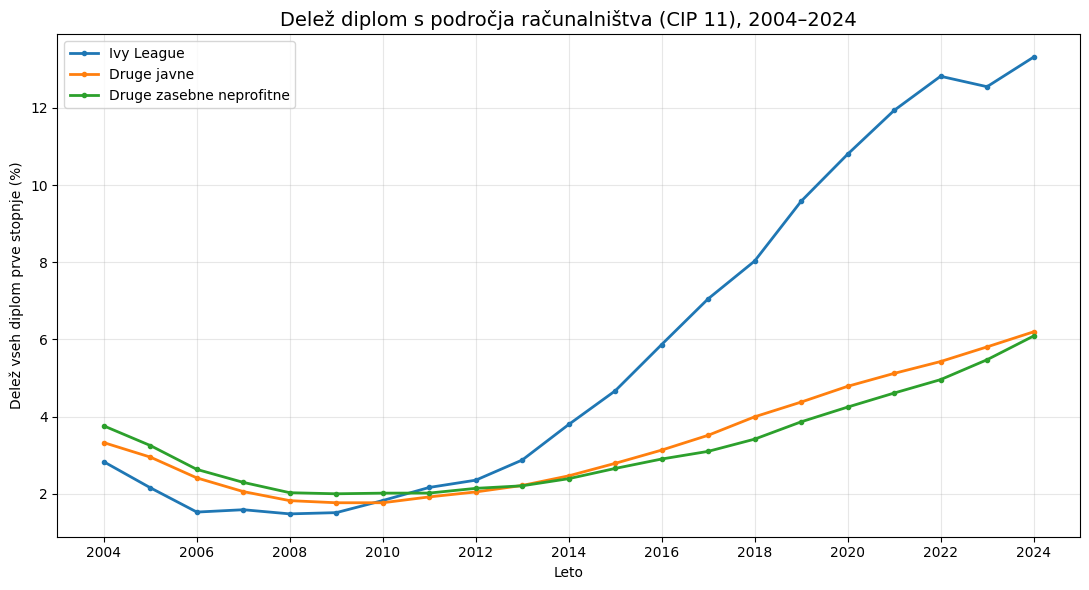

In [28]:
#priprava grafa deleža diplom cip 11 po skupinah univerz
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

#določitev vrstnega reda skupin
skupine = [
    "Ivy League",
    "Druge javne",
    "Druge zasebne neprofitne"
]

#risanje črt za posamezne skupine univerz
for skupina in skupine:
    podatki = rv4_trendi[
        rv4_trendi["skupina"] == skupina
    ].sort_values("leto")

    plt.plot(
        podatki["leto"],
        podatki["delez_cip11"],
        marker="o",
        markersize=3,
        linewidth=2,
        label=skupina
    )

#oblikovanje grafa
plt.title(
    "Delež diplom s področja računalništva (CIP 11), 2004–2024",
    fontsize=14
)
plt.xlabel("Leto")
plt.ylabel("Delež vseh diplom prve stopnje (%)")
plt.xticks(range(2004, 2025, 2))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

#shranjevanje grafa
plt.savefig("RV4_delez_diplom_cip11.png", dpi=300, bbox_inches="tight")

plt.show()

RV2: kako se je spreminjala stopnja zaključevanja študija?

In [30]:
#nalaganje podatkov za rv2
df_rv2 = pd.read_csv(
    "/content/IPEDS_RV2.csv",
    low_memory=False
)



Dimenzije zbirke: (867970, 8)

Stolpci:
['UNITID', 'GRTYPE', 'CHRTSTAT', 'SECTION', 'COHORT', 'GRTOTLT', 'leto', 'vir']

Obdobje:
2008 - 2024


,UNITID,GRTYPE,CHRTSTAT,SECTION,COHORT,GRTOTLT,leto,vir
0,100654,2,12,1,1,1043,2008,GR2008
1,100654,3,13,1,1,339,2008,GR2008
2,100654,6,10,2,2,1043,2008,GR2008
3,100654,8,12,2,2,1043,2008,GR2008
4,100654,9,13,2,2,339,2008,GR2008


In [32]:
#preoblikovanje podatkov v eno vrstico za vsako univerzo in leto
df_rv2_siroko = df_rv2_izbor.pivot(
    index=["UNITID", "leto"],
    columns="kazalnik",
    values="GRTOTLT"
).reset_index()

#odstranitev imena osi, ki nastane pri preoblikovanju
df_rv2_siroko.columns.name = None

#preverjanje razpoložljivosti obeh kazalnikov
print("Število zapisov:", len(df_rv2_siroko))

print("\nManjkajoči podatki o kohorti:")
print(df_rv2_siroko["kohorta"].isna().sum())

print("\nManjkajoči podatki o zaključenih študentih:")
print(df_rv2_siroko["zakljucili"].isna().sum())

#preverjanje neveljavnih kombinacij
print("\nZapisi, kjer je zaključenih več študentov kot v kohorti:")
print(
    (
        df_rv2_siroko["zakljucili"] >
        df_rv2_siroko["kohorta"]
    ).sum()
)

#preverjanje kohort brez študentov
print("\nZapisi z ničelno kohorto:")
print((df_rv2_siroko["kohorta"] == 0).sum())

#pregled prvih petih zapisov
display(df_rv2_siroko.head())

Število zapisov: 40011

Manjkajoči podatki o kohorti:
0

Manjkajoči podatki o zaključenih študentih:
653

Zapisi, kjer je zaključenih več študentov kot v kohorti:
0

Zapisi z ničelno kohorto:
1


,UNITID,leto,kohorta,zakljucili
0,100654,2008,1043.0,339.0
1,100654,2009,1287.0,370.0
2,100654,2010,1198.0,396.0
3,100654,2011,1088.0,345.0
4,100654,2012,1133.0,365.0


potrebujem oba podatka

In [33]:
#izbor zapisov s popolnimi podatki in pozitivno kohorto
df_rv2_analiza = df_rv2_siroko[
    (df_rv2_siroko["kohorta"] > 0) &
    (df_rv2_siroko["zakljucili"].notna())
].copy()

#izračun stopnje zaključevanja študija v 150 % predvidenega časa
df_rv2_analiza["stopnja_zakljucevanja"] = (
    df_rv2_analiza["zakljucili"] /
    df_rv2_analiza["kohorta"]
) * 100

#preverjanje rezultatov
print("Število veljavnih zapisov:", len(df_rv2_analiza))

print("\nOpisna statistika stopnje zaključevanja:")
display(df_rv2_analiza["stopnja_zakljucevanja"].describe())

print("\nStopnje zunaj intervala 0–100 %:")
print(
    (
        (df_rv2_analiza["stopnja_zakljucevanja"] < 0) |
        (df_rv2_analiza["stopnja_zakljucevanja"] > 100)
    ).sum()
)

#pregled prvih petih zapisov
display(df_rv2_analiza.head())

Število veljavnih zapisov: 39358

Opisna statistika stopnje zaključevanja:


,stopnja_zakljucevanja
count,39358.000000
mean,50.254393
std,21.130575
min,0.636943
25%,34.676303
50%,50.000000
75%,65.052150
max,100.000000



Stopnje zunaj intervala 0–100 %:
0


,UNITID,leto,kohorta,zakljucili,stopnja_zakljucevanja
0,100654,2008,1043.0,339.0,32.502397
1,100654,2009,1287.0,370.0,28.749029
2,100654,2010,1198.0,396.0,33.055092
3,100654,2011,1088.0,345.0,31.709559
4,100654,2012,1133.0,365.0,32.215357


In [34]:
#povezovanje stopenj zaključevanja z institucionalnimi podatki
df_rv2_povezano = df_rv2_analiza.merge(
    df_institucije[
        ["UNITID", "leto", "INSTNM", "CONTROL", "ICLEVEL"]
    ],
    on=["UNITID", "leto"],
    how="left",
    validate="one_to_one",
    indicator=True
)

#preverjanje uspešnosti povezovanja
print("Uspešnost povezovanja:")
print(df_rv2_povezano["_merge"].value_counts())

#preverjanje manjkajočih institucionalnih podatkov
print("\nManjkajoče vrednosti CONTROL:")
print(df_rv2_povezano["CONTROL"].isna().sum())

print("\nManjkajoče vrednosti ICLEVEL:")
print(df_rv2_povezano["ICLEVEL"].isna().sum())

#pregled prvih petih povezanih zapisov
display(df_rv2_povezano.head())

Uspešnost povezovanja:
_merge
both          39358
left_only         0
right_only        0
Name: count, dtype: int64

Manjkajoče vrednosti CONTROL:
0

Manjkajoče vrednosti ICLEVEL:
0


,UNITID,leto,kohorta,zakljucili,stopnja_zakljucevanja,INSTNM,CONTROL,ICLEVEL,_merge
0,100654,2008,1043.0,339.0,32.502397,Alabama A & M University,1,1,both
1,100654,2009,1287.0,370.0,28.749029,Alabama A & M University,1,1,both
2,100654,2010,1198.0,396.0,33.055092,Alabama A & M University,1,1,both
3,100654,2011,1088.0,345.0,31.709559,Alabama A & M University,1,1,both
4,100654,2012,1133.0,365.0,32.215357,Alabama A & M University,1,1,both


In [35]:
#izbor štiriletnih javnih in zasebnih neprofitnih univerz
df_rv2_skupine = df_rv2_povezano[
    (df_rv2_povezano["ICLEVEL"] == 1) &
    (df_rv2_povezano["CONTROL"].isin([1, 2]))
].copy()

#razvrstitev univerz v tri primerjalne skupine
df_rv2_skupine["skupina"] = "Druge zasebne neprofitne"

df_rv2_skupine.loc[
    df_rv2_skupine["CONTROL"] == 1, "skupina"
] = "Druge javne"

df_rv2_skupine.loc[
    df_rv2_skupine["UNITID"].isin(ivy_unitid), "skupina"
] = "Ivy League"

#preverjanje števila univerz po skupinah in letih
pregled_rv2_skupin = df_rv2_skupine.groupby(
    ["leto", "skupina"]
)["UNITID"].nunique().unstack()

print("Število univerz po skupinah in letih:")
display(pregled_rv2_skupin)

#preverjanje prisotnosti vseh osmih univerz ivy league
print("\nŠtevilo univerz Ivy League po letih:")
print(pregled_rv2_skupin["Ivy League"])

#preverjanje skupnega števila zapisov
print("\nŠtevilo zapisov po filtriranju:", len(df_rv2_skupine))

Število univerz po skupinah in letih:


skupina,Druge javne,Druge zasebne neprofitne,Ivy League
leto,,,
2008,616,1240,8
2009,634,1226,8
2010,641,1234,8
2011,642,1245,8
2012,656,1244,8
2013,660,1271,8
2014,672,1263,8
2015,676,1278,8
2016,703,1271,8



Število univerz Ivy League po letih:
leto
2008    8
2009    8
2010    8
2011    8
2012    8
2013    8
2014    8
2015    8
2016    8
2017    8
2018    8
2019    8
2020    8
2021    8
2022    8
2023    8
2024    8
Name: Ivy League, dtype: int64

Število zapisov po filtriranju: 33284


In [36]:
#seštevanje kohort in zaključenih študentov po skupinah in letih
rv2_trendi = df_rv2_skupine.groupby(
    ["leto", "skupina"],
    as_index=False
)[["kohorta", "zakljucili"]].sum()

#izračun utežene stopnje zaključevanja
rv2_trendi["stopnja_zakljucevanja"] = (
    rv2_trendi["zakljucili"] /
    rv2_trendi["kohorta"]
) * 100

#pregled rezultatov za začetno in končno leto
print("Stopnje zaključevanja v letih 2008 in 2024:")
display(
    rv2_trendi[
        rv2_trendi["leto"].isin([2008, 2024])
    ].sort_values(["skupina", "leto"])
)

#pregled gibanja stopenj skozi celotno obdobje
print("\nStopnje zaključevanja po letih in skupinah:")
display(
    rv2_trendi.pivot(
        index="leto",
        columns="skupina",
        values="stopnja_zakljucevanja"
    ).round(2)
)

Stopnje zaključevanja v letih 2008 in 2024:


,leto,skupina,kohorta,zakljucili,stopnja_zakljucevanja
0,2008,Druge javne,880282.0,467866.0,53.149559
48,2024,Druge javne,1278662.0,751630.0,58.782540
1,2008,Druge zasebne neprofitne,437856.0,270645.0,61.811417
49,2024,Druge zasebne neprofitne,513206.0,338864.0,66.028846
2,2008,Ivy League,13357.0,12671.0,94.864116
50,2024,Ivy League,14659.0,14100.0,96.186643



Stopnje zaključevanja po letih in skupinah:


skupina,Druge javne,Druge zasebne neprofitne,Ivy League
leto,,,
2008,53.15,61.81,94.86
2009,53.31,61.92,94.84
2010,53.42,62.17,94.89
2011,54.03,61.78,95.09
2012,54.62,62.36,95.31
2013,54.88,62.19,95.25
2014,55.34,62.22,95.38
2015,54.99,61.80,95.42
2016,54.58,61.98,95.65


Primerjava med skupinami univerz:

Ivy League ima izrazito višjo stopnjo zaključevanja študija. - Leta 2024 je na Ivy League v 150 % predvidenega časa študij zaključilo približno 96 % študentov iz obravnavanih kohort. Pri drugih javnih univerzah je bila stopnja približno 59 %, pri zasebnih neprofitnih pa 66 %.

Primerjava skozi čas:

Stopnja zaključevanja se je povečala v vseh treh skupinah. Največje izboljšanje v odstotnih točkah so dosegle druge javne univerze.

Ivy League je imela visoko stopnjo zaključevanja že na začetku obdobja, zato je bil prostor za nadaljnje povečanje manjši. Stopnja se je skozi celotno obdobje gibala približno med 95 % in 96 %.


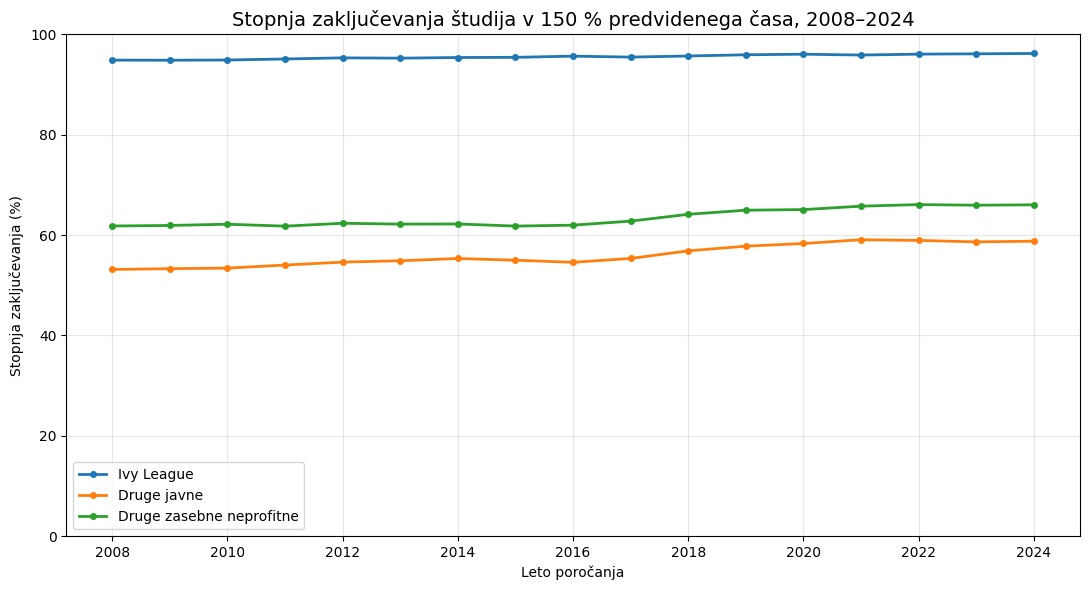

In [37]:
#priprava grafa stopnje zaključevanja študija po skupinah univerz
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

#določitev vrstnega reda skupin
skupine = [
    "Ivy League",
    "Druge javne",
    "Druge zasebne neprofitne"
]

#risanje črt za posamezne skupine univerz
for skupina in skupine:
    podatki = rv2_trendi[
        rv2_trendi["skupina"] == skupina
    ].sort_values("leto")

    plt.plot(
        podatki["leto"],
        podatki["stopnja_zakljucevanja"],
        marker="o",
        markersize=4,
        linewidth=2,
        label=skupina
    )

#oblikovanje grafa
plt.title(
    "Stopnja zaključevanja študija v 150 % predvidenega časa, 2008–2024",
    fontsize=14
)
plt.xlabel("Leto poročanja")
plt.ylabel("Stopnja zaključevanja (%)")
plt.xticks(range(2008, 2025, 2))
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

#shranjevanje grafa
plt.savefig(
    "figures/RV2_stopnja_zakljucevanja.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

- Ivy League: stopnja zaključevanja je skozi celotno obdobje zelo visoka in stabilna (približno 95–96 %).
- Druge javne univerze: stopnja se je povečala s 53,15 % na 58,78 %.
- Druge zasebne neprofitne univerze: stopnja se je povečala z 61,81 % na 66,03 %.

In [38]:
#shranjevanje rezultatov rv2 po skupinah in letih
import os

#ustvarjanje mape za obdelane podatke
os.makedirs("data/processed", exist_ok=True)

#shranjevanje podatkov o stopnjah zaključevanja
rv2_trendi.to_csv(
    "data/processed/RV2_trendi_zakljucevanja_2008_2024.csv",
    index=False
)

#preverjanje shranjene datoteke
print("Datoteka uspešno shranjena:")
print(os.path.exists(
    "data/processed/RV2_trendi_zakljucevanja_2008_2024.csv"
))

Datoteka uspešno shranjena:
True
